<a href="https://colab.research.google.com/github/vinayp1210/Iris_Species_analyses/blob/main/Iris_Species_Analysis_Vinay_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import libraries and prepare output folders
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

os.makedirs("graphs", exist_ok=True)
os.makedirs("dataset", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# 2. Load the dataset already uploaded in Google Colab
# Select the uploaded Iris CSV file automatically.
import glob

csv_files = glob.glob("/content/*.csv")
if not csv_files:
    raise FileNotFoundError("Upload your Iris CSV dataset to Google Colab first.")

# Prefer Iris.csv if present; otherwise use the first uploaded CSV.
iris_files = [f for f in csv_files if "iris" in os.path.basename(f).lower()]
dataset_path = iris_files[0] if iris_files else csv_files[0]
df_raw = pd.read_csv(dataset_path)

print("Dataset loaded from:", dataset_path)
print("Dataset shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Dataset loaded from: /content/Iris.csv
Dataset shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# 3. Standardize column names to the project proposal's feature names
df = df_raw.copy()
df.columns = [str(c).strip().lower().replace(" ", "").replace("_", "") for c in df.columns]

# Map Kaggle Iris.csv columns and common alternative column names
column_map = {
    "id": "Id",
    "sepallengthcm": "SepalLengthCm",
    "sepalwidthcm": "SepalWidthCm",
    "petallengthcm": "PetalLengthCm",
    "petalwidthcm": "PetalWidthCm",
    "species": "Species",
    "class": "Species",
    "sepallength": "SepalLengthCm",
    "sepalwidth": "SepalWidthCm",
    "petallength": "PetalLengthCm",
    "petalwidth": "PetalWidthCm"
}
df = df.rename(columns={c: column_map[c] for c in df.columns if c in column_map})

# Some versions use a capitalized "Species" or "species"; mapping above standardizes it.
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
missing_required = [c for c in feature_cols + ["Species"] if c not in df.columns]
if missing_required:
    raise ValueError(
        f"Required columns not found: {missing_required}. "
        f"Detected columns: {df.columns.tolist()}. Please upload the Kaggle Iris.csv file."
    )

# Identifier is not a measurement and is excluded from analysis.
if "Id" in df.columns:
    df["Id"] = pd.to_numeric(df["Id"], errors="coerce")

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Species"] = df["Species"].astype("string").str.strip()
print("Standardized columns:", df.columns.tolist())
display(df.head())
df.info()

Standardized columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    string 
dtypes: float64(4), int64(1), string(1)
memory usage: 7.2 KB


In [6]:
# 4. Initial data quality report
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nData types:")
display(df.dtypes.astype(str).to_frame("Data type"))

print("\nSpecies counts:")
display(df["Species"].value_counts(dropna=False).to_frame("Count"))

print("\nNumerical summary:")
display(df[feature_cols].describe().T)

Missing values by column:


,Missing values
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


Exact duplicate rows: 0

Data types:


,Data type
Id,int64
SepalLengthCm,float64
SepalWidthCm,float64
PetalLengthCm,float64
PetalWidthCm,float64
Species,string



Species counts:


,Count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
SepalLengthCm,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
SepalWidthCm,150.0,3.054000,0.433594,2.0,2.8,3.00,3.3,4.4
PetalLengthCm,150.0,3.758667,1.764420,1.0,1.6,4.35,5.1,6.9
PetalWidthCm,150.0,1.198667,0.763161,0.1,0.3,1.30,1.8,2.5


In [7]:
# 5. Clean missing values, duplicate rows, data types, and invalid values
rows_before = len(df)
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)

# Treat impossible/non-positive flower measurements as invalid and set them to missing.
invalid_counts = {}
for col in feature_cols:
    invalid_mask = df[col].notna() & (df[col] <= 0)
    invalid_counts[col] = int(invalid_mask.sum())
    df.loc[invalid_mask, col] = np.nan

# Impute missing numerical measurements with their column median.
for col in feature_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing species with the most frequent species, if any.
if df["Species"].isna().any():
    species_mode = df["Species"].mode(dropna=True)
    if len(species_mode):
        df["Species"] = df["Species"].fillna(species_mode.iloc[0])

# Drop any rows that still have missing required data.
df = df.dropna(subset=feature_cols + ["Species"]).copy()

# Remove common accidental index columns; retain Id if it exists for reference only.
extra_index_cols = [c for c in df.columns if c.lower().startswith("unnamed")]
if extra_index_cols:
    df = df.drop(columns=extra_index_cols)

print("Duplicate rows removed:", duplicates_removed)
print("Invalid non-positive measurements found:", invalid_counts)
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("Missing values"))
print("Cleaned dataset shape:", df.shape)
display(df.head())

Duplicate rows removed: 0
Invalid non-positive measurements found: {'SepalLengthCm': 0, 'SepalWidthCm': 0, 'PetalLengthCm': 0, 'PetalWidthCm': 0}

Missing values after cleaning:


,Missing values
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


Cleaned dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
# 6. Outlier detection using the IQR method
# Outliers are flagged for review, not automatically deleted.
outlier_rows = []
outlier_mask_all = pd.Series(False, index=df.index)

for col in feature_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_mask_all = outlier_mask_all | mask
    outlier_rows.append({
        "Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower bound": lower, "Upper bound": upper,
        "Potential outliers": int(mask.sum())
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

print("Rows with one or more potential outlier measurements:")
display(df.loc[outlier_mask_all, ["Species"] + feature_cols])

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Potential outliers
0,SepalLengthCm,5.1,6.4,1.3,3.15,8.35,0
1,SepalWidthCm,2.8,3.3,0.5,2.05,4.05,4
2,PetalLengthCm,1.6,5.1,3.5,-3.65,10.35,0
3,PetalWidthCm,0.3,1.8,1.5,-1.95,4.05,0


Rows with one or more potential outlier measurements:


,Species,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
15,Iris-setosa,5.7,4.4,1.5,0.4
32,Iris-setosa,5.2,4.1,1.5,0.1
33,Iris-setosa,5.5,4.2,1.4,0.2
60,Iris-versicolor,5.0,2.0,3.5,1.0


## 7. Visualizations
The following charts match the project proposal: species count, feature distributions, outlier box plots, sepal scatter plot, petal scatter plot, average measurements by species, pair plot, and correlation heatmap.

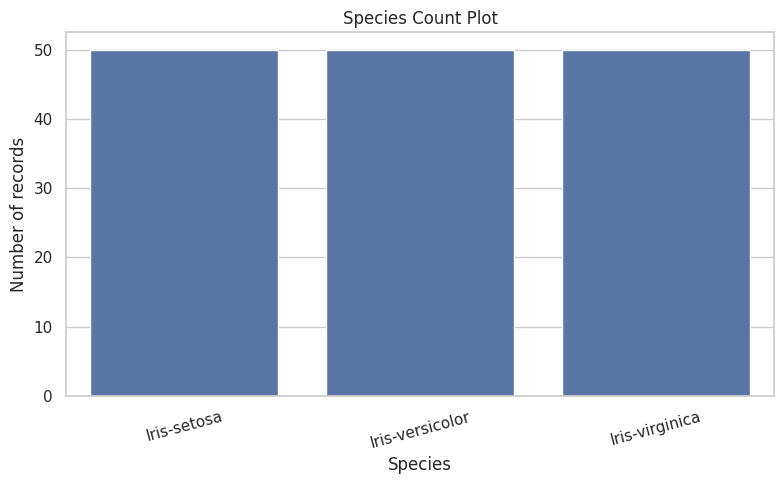

In [9]:
# Visualization 1 — Species Count Plot
plt.figure(figsize=(8, 5))
order = df["Species"].value_counts().index
sns.countplot(data=df, x="Species", order=order)
plt.title("Species Count Plot")
plt.xlabel("Species")
plt.ylabel("Number of records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("graphs/species_count.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 2 — Feature Distributions (histograms with KDE)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(feature_cols, axes.flatten()):
    sns.histplot(data=df, x=col, hue="Species", kde=True, element="step",
                 stat="count", common_norm=False, ax=ax)
    ax.set_title(f"Distribution of {col}")
fig.suptitle("Distribution of Iris Measurements", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig("graphs/feature_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 3 — Box plots for outlier detection (overall and grouped by species)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(feature_cols, axes.flatten()):
    sns.boxplot(data=df, x="Species", y=col, ax=ax)
    ax.set_title(f"{col} by Species")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Outlier Detection and Measurement Spread", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig("graphs/outlier_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 4 — Sepal Length vs Sepal Width
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="SepalLengthCm", y="SepalWidthCm", hue="Species", s=75)
plt.title("Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.tight_layout()
plt.savefig("graphs/scatter_sepal.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 5 — Petal Length vs Petal Width
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="PetalLengthCm", y="PetalWidthCm", hue="Species", s=75)
plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.savefig("graphs/scatter_petal.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 6 — Average Measurements by Species (grouped bar chart)
mean_by_species = df.groupby("Species")[feature_cols].mean().reset_index()
mean_long = mean_by_species.melt(id_vars="Species", var_name="Measurement", value_name="Average (cm)")

plt.figure(figsize=(12, 6))
sns.barplot(data=mean_long, x="Measurement", y="Average (cm)", hue="Species")
plt.title("Average Measurements by Species")
plt.xlabel("Measurement")
plt.ylabel("Average (cm)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("graphs/average_by_species.png", dpi=200, bbox_inches="tight")
plt.show()
display(mean_by_species.round(2))

In [ ]:
# Visualization 7 — Pair Plot
pair_grid = sns.pairplot(df, vars=feature_cols, hue="Species", diag_kind="hist", corner=False)
pair_grid.fig.suptitle("Pair Plot of Iris Measurements", y=1.02)
pair_grid.savefig("graphs/pairplot.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Visualization 8 — Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation = df[feature_cols].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Iris Measurements")
plt.tight_layout()
plt.savefig("graphs/correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()
display(correlation.round(2))

In [ ]:
# 8. Short insights report — calculated from this dataset
print("=" * 68)
print("IRIS SPECIES ANALYSIS — INSIGHTS REPORT")
print("=" * 68)
print(f"Records after cleaning: {len(df)}")
print(f"Number of species: {df['Species'].nunique()}")
print(f"Duplicate rows removed: {duplicates_removed}")
print(f"Missing values remaining: {int(df.isna().sum().sum())}")

print("\n1. Species counts:")
print(df["Species"].value_counts().to_string())

print("\n2. Average measurements by species (cm):")
print(mean_by_species.set_index("Species").round(2).to_string())

print("\n3. Species with the smallest and largest mean for each measurement:")
for col in feature_cols:
    means = df.groupby("Species")[col].mean()
    print(f"- {col}: smallest = {means.idxmin()} ({means.min():.2f}), "
          f"largest = {means.idxmax()} ({means.max():.2f})")

print("\n4. Strongest relationship between two different measurements:")
corr_abs = correlation.abs().copy()
np.fill_diagonal(corr_abs.values, 0)
feature_pair = corr_abs.stack().idxmax()
corr_value = correlation.loc[feature_pair[0], feature_pair[1]]
print(f"- {feature_pair[0]} and {feature_pair[1]}: correlation = {corr_value:.2f}")

print("\n5. Potential outliers by feature (IQR method):")
print(outlier_summary[["Feature", "Potential outliers"]].to_string(index=False))

print("\n6. Interpretation:")
print("- Use the count plot to assess whether the species classes are balanced.")
print("- Histograms show the spread and shape of each measurement distribution.")
print("- Box plots flag unusual values for review; a flagged value is not automatically an error.")
print("- Compare the sepal and petal scatter plots to see which measurements separate species more clearly.")
print("- The pair plot and heatmap summarize feature relationships and correlations.")
print("=" * 68)

In [ ]:
# 9. Save cleaned data, outlier rows, summary tables, and graph files
df.to_csv("dataset/Iris_cleaned.csv", index=False)
df.loc[outlier_mask_all].to_csv("dataset/Iris_potential_outliers.csv", index=False)
mean_by_species.to_csv("dataset/average_measurements_by_species.csv", index=False)
outlier_summary.to_csv("dataset/outlier_summary.csv", index=False)
correlation.to_csv("dataset/feature_correlation.csv")

print("Saved outputs:")
for root, dirs, files_list in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]
    for filename in files_list:
        if root.startswith("./graphs") or root.startswith("./dataset"):
            print(os.path.join(root, filename))

## Conclusion
This notebook follows the project proposal by performing data quality checks, cleaning the dataset, detecting potential outliers, creating the eight specified visualizations, and producing a short insights report. Run the notebook to generate results from the uploaded dataset. Potential outliers are reported for investigation rather than removed automatically.